**Task 1 — Load the cleaned dataset**

In [1]:
import pandas as pd

df = pd.read_csv("../data/telco_customer_churn_cleaned.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


**Task 1: Calculate Overall Churn Rate**

In [2]:
total_customers = df["customerID"].nunique()

churned_customers = (df["Churn"] == "Yes").sum()

retained_customers = (df["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %
Retention Rate: 73.46 %


**Task 2 — Visualize Churn Distribution**

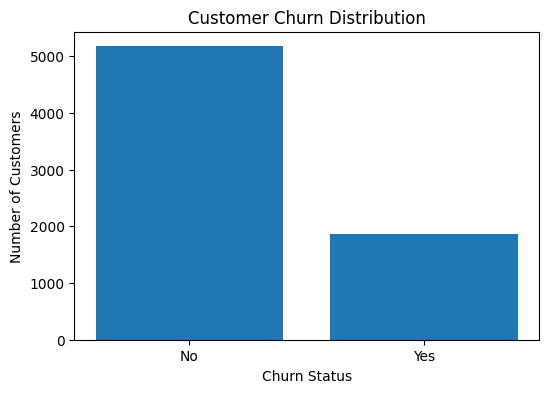

In [3]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

**Task 3: Churn by Customer Segment.**

In [4]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


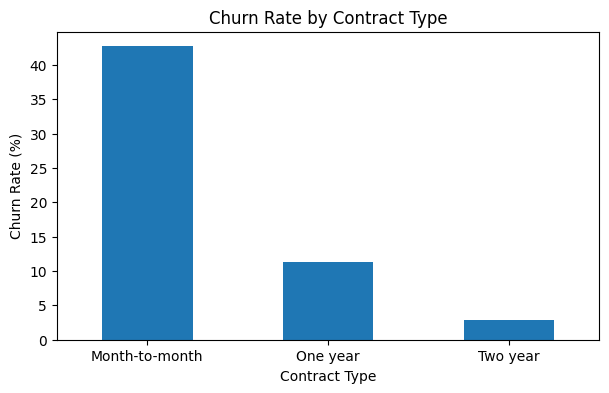

In [5]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

**Task 4 — Churn by Tenure**

In [6]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(tenure_churn.round(2))

Churn            No    Yes
TenureGroup               
0-12 months   52.56  47.44
13-24 months  71.29  28.71
25-48 months  79.61  20.39
49-72 months  90.49   9.51


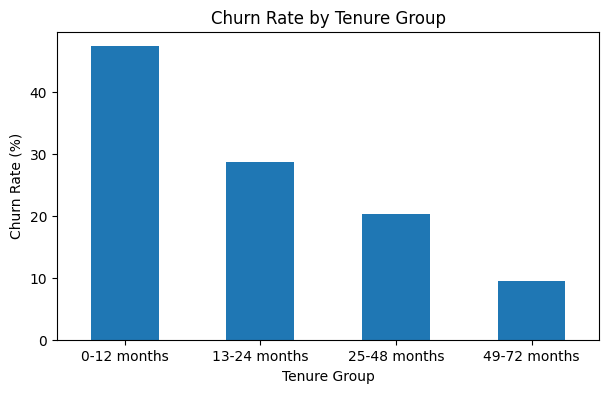

In [7]:
tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

**Task 5 — Churn by Internet Service**

In [8]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


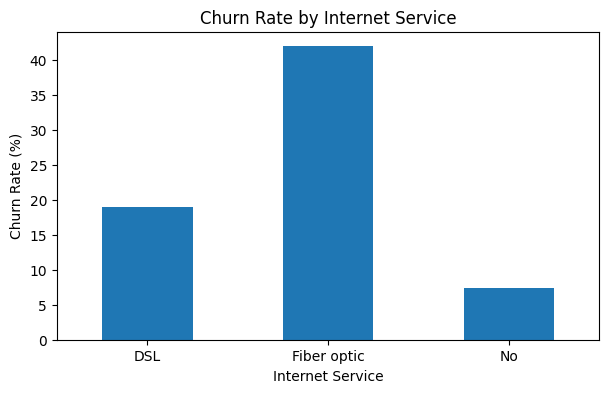

In [9]:
internet_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

**Payment Method**

In [10]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


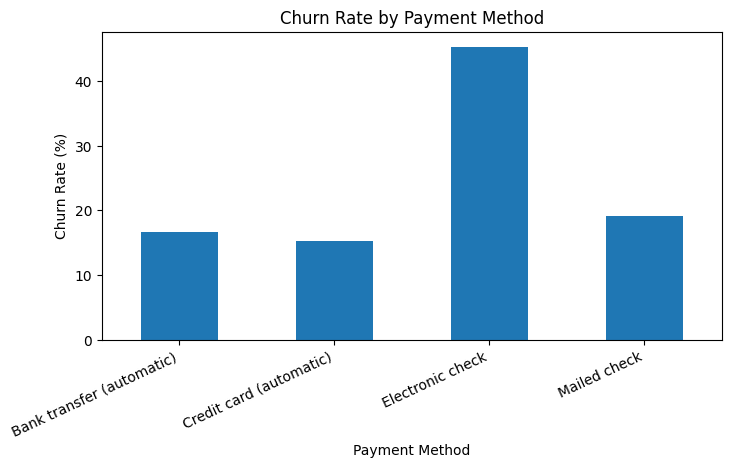

In [11]:
payment_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")

plt.show()

**Task 6 — Monthly Charges vs Churn**

In [12]:
monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].mean()

print(monthly_charges_churn.round(2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


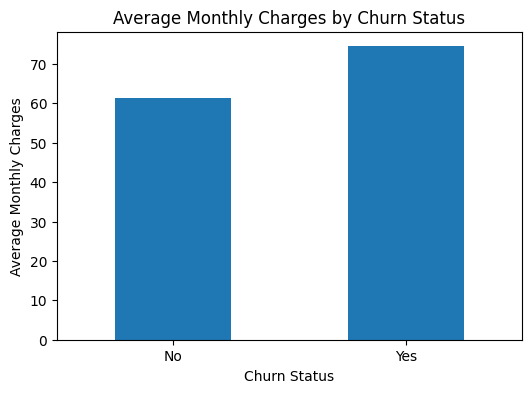

In [13]:
monthly_charges_churn.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)

plt.show()

**Task 7 — Total Charges vs Churn**

In [14]:
total_charges_churn = df.groupby("Churn")["TotalCharges"].mean()

print(total_charges_churn.round(2))

Churn
No     2555.34
Yes    1531.80
Name: TotalCharges, dtype: float64


**Customer Profile**

In [15]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn.round(2))

Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


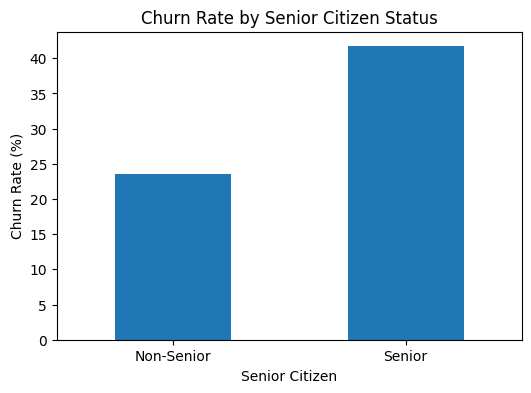

In [16]:
senior_churn["Yes"].plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")
plt.xticks(
    ticks=[0, 1],
    labels=["Non-Senior", "Senior"],
    rotation=0
)

plt.show()

**Task 8 — Partner & Dependents**

In [17]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print("Partner:")
print(partner_churn.round(2))

print("\nDependents:")
print(dependents_churn.round(2))

Partner:
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

Dependents:
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


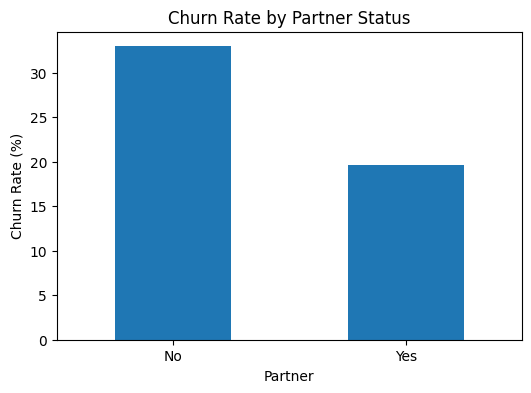

In [18]:
partner_churn["Yes"].plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

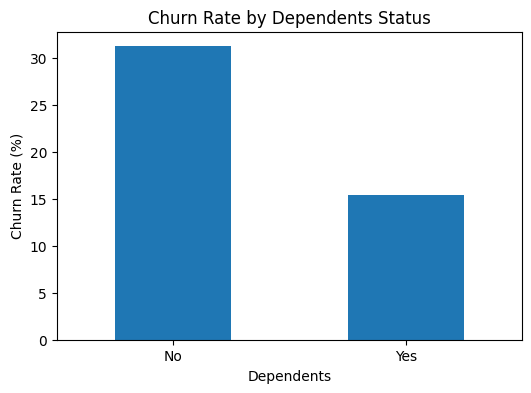

In [19]:
dependents_churn["Yes"].plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Churn Rate by Dependents Status")
plt.xlabel("Dependents")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

**Task 9 — Churn by Additional Services**

In [20]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport"
]

for col in service_columns:
    service_churn = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    print("\n", col)
    print(service_churn.round(2))


 OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

 OnlineBackup
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53

 DeviceProtection
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50

 TechSupport
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


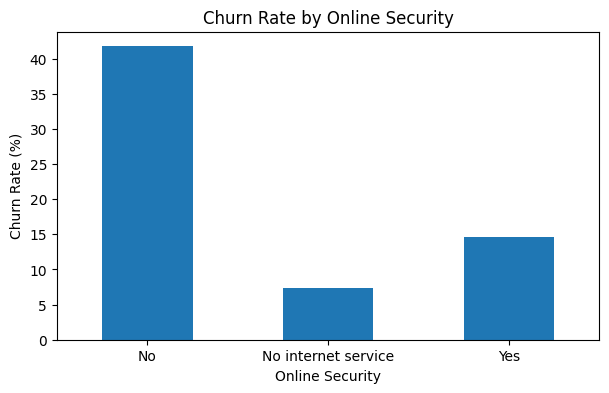

In [21]:
online_security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

online_security_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

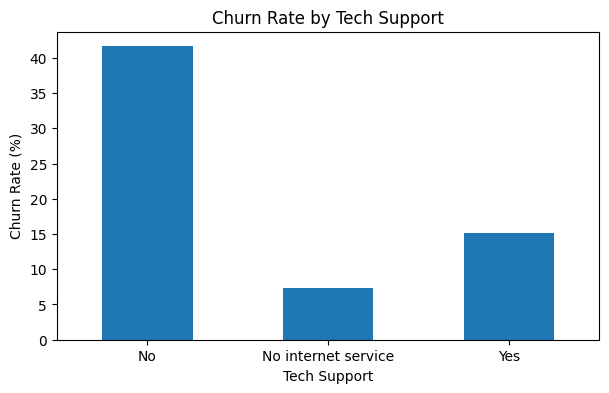

In [22]:
tech_support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

tech_support_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

**Task 12 — Contract + Internet Service**

In [23]:
contract_internet_churn = pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize="index"
) * 100

print(contract_internet_churn.round(2))

Churn                              No    Yes
Contract       InternetService              
Month-to-month DSL              67.78  32.22
               Fiber optic      45.39  54.61
               No               81.11  18.89
One year       DSL              90.70   9.30
               Fiber optic      80.71  19.29
               No               97.53   2.47
Two year       DSL              98.09   1.91
               Fiber optic      92.77   7.23
               No               99.22   0.78


In [24]:
high_risk_segment = df[
    (df["Contract"] == "Month-to-month") &
    (df["InternetService"] == "Fiber optic")
]

print("Customers in high-risk segment:", high_risk_segment.shape[0])
print("Churned customers:", (high_risk_segment["Churn"] == "Yes").sum())
print("Retained customers:", (high_risk_segment["Churn"] == "No").sum())

Customers in high-risk segment: 2128
Churned customers: 1162
Retained customers: 966


**EDA Task 13 — High-risk segment profile**

In [25]:
print("Average Tenure:",
      round(high_risk_segment["tenure"].mean(), 2))

print("Average Monthly Charges:",
      round(high_risk_segment["MonthlyCharges"].mean(), 2))

print("\nPayment Method:")
print(high_risk_segment["PaymentMethod"].value_counts())

print("\nOnline Security:")
print(high_risk_segment["OnlineSecurity"].value_counts())

print("\nTech Support:")
print(high_risk_segment["TechSupport"].value_counts())

Average Tenure: 21.55
Average Monthly Charges: 87.02

Payment Method:
PaymentMethod
Electronic check             1307
Bank transfer (automatic)     327
Credit card (automatic)       293
Mailed check                  201
Name: count, dtype: int64

Online Security:
OnlineSecurity
No     1774
Yes     354
Name: count, dtype: int64

Tech Support:
TechSupport
No     1796
Yes     332
Name: count, dtype: int64


**Task 14 — Revenue at Risk**

In [26]:
churned_customers_df = df[df["Churn"] == "Yes"]

monthly_revenue_lost = churned_customers_df["MonthlyCharges"].sum()

print("Churned Customers:", churned_customers_df.shape[0])
print("Monthly Charges of Churned Customers:",
      round(monthly_revenue_lost, 2))

Churned Customers: 1869
Monthly Charges of Churned Customers: 139130.85


T**ask 14 — Calculate the percentage of monthly charges associated with churned customers**

In [27]:
total_monthly_charges = df["MonthlyCharges"].sum()

churned_monthly_charges = df.loc[
    df["Churn"] == "Yes",
    "MonthlyCharges"
].sum()

churned_revenue_share = (
    churned_monthly_charges / total_monthly_charges
) * 100

print("Total Monthly Charges:",
      round(total_monthly_charges, 2))

print("Churned Customer Monthly Charges:",
      round(churned_monthly_charges, 2))

print("Share of Monthly Charges Associated with Churned Customers:",
      round(churned_revenue_share, 2), "%")

Total Monthly Charges: 456116.6
Churned Customer Monthly Charges: 139130.85
Share of Monthly Charges Associated with Churned Customers: 30.5 %


**Task 15 — Current high-risk customers and potential revenue exposure**

In [28]:
high_risk_retained = df[
    (df["Contract"] == "Month-to-month") &
    (df["InternetService"] == "Fiber optic") &
    (df["Churn"] == "No")
]

print("High-risk retained customers:", high_risk_retained.shape[0])

print("Monthly charges of high-risk retained customers:",
      round(high_risk_retained["MonthlyCharges"].sum(), 2))

High-risk retained customers: 966
Monthly charges of high-risk retained customers: 84699.1


In [29]:
high_risk_revenue_share = (
    high_risk_retained["MonthlyCharges"].sum()
    / df["MonthlyCharges"].sum()
) * 100

print(
    "High-risk retained monthly charges share:",
    round(high_risk_revenue_share, 2),
    "%"
)

High-risk retained monthly charges share: 18.57 %


**Task 16 — Profile the 966 retained high-risk customers**

In [30]:
print("Average Tenure:",
      round(high_risk_retained["tenure"].mean(), 2))

print("Average Monthly Charges:",
      round(high_risk_retained["MonthlyCharges"].mean(), 2))

Average Tenure: 27.91
Average Monthly Charges: 87.68


In [31]:
print(
    high_risk_retained["PaymentMethod"].value_counts()
)

PaymentMethod
Electronic check             518
Bank transfer (automatic)    178
Credit card (automatic)      171
Mailed check                  99
Name: count, dtype: int64


**Online Security**

In [32]:
print(
    high_risk_retained["OnlineSecurity"].value_counts()
)

OnlineSecurity
No     743
Yes    223
Name: count, dtype: int64


**Tech Support**

In [33]:
print(
    high_risk_retained["TechSupport"].value_counts()
)

TechSupport
No     763
Yes    203
Name: count, dtype: int64


In [34]:
risk_conditions = (
    (df["Contract"] == "Month-to-month").astype(int)
    + (df["InternetService"] == "Fiber optic").astype(int)
    + (df["PaymentMethod"] == "Electronic check").astype(int)
    + (df["OnlineSecurity"] == "No").astype(int)
    + (df["TechSupport"] == "No").astype(int)
)

df["RiskFactorCount"] = risk_conditions

print(df["RiskFactorCount"].value_counts().sort_index())

RiskFactorCount
0    1492
1    1260
2    1004
3    1098
4    1200
5     989
Name: count, dtype: int64


**Calculate churn rate by RiskFactorCount**

In [35]:
risk_churn = pd.crosstab(
    df["RiskFactorCount"],
    df["Churn"],
    normalize="index"
) * 100

print(risk_churn.round(2))

Churn               No    Yes
RiskFactorCount              
0                97.99   2.01
1                88.41  11.59
2                84.06  15.94
3                70.95  29.05
4                53.08  46.92
5                34.18  65.82


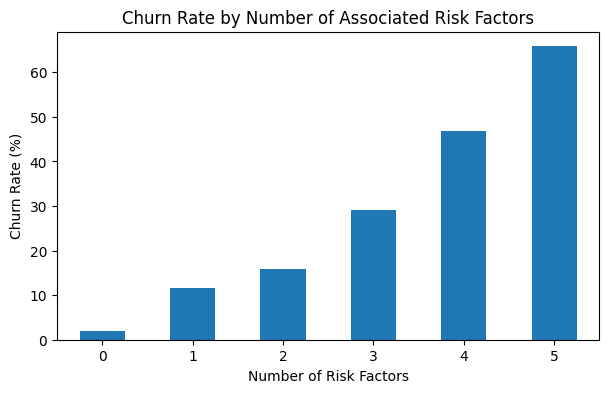

In [36]:
risk_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Number of Associated Risk Factors")
plt.xlabel("Number of Risk Factors")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

**Step 1 — Build segment-level churn analysis**

In [37]:
segment_analysis = (
    df.groupby(
        ["Contract", "InternetService", "PaymentMethod"]
    )
    .agg(
        Customers=("customerID", "count"),
        Churned=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

segment_analysis["ChurnRate"] = (
    segment_analysis["Churned"]
    / segment_analysis["Customers"]
) * 100

segment_analysis = segment_analysis.sort_values(
    "ChurnRate",
    ascending=False
)

print(segment_analysis.round(2).head(10))

          Contract InternetService              PaymentMethod  Customers  \
6   Month-to-month     Fiber optic           Electronic check       1307   
7   Month-to-month     Fiber optic               Mailed check        201   
4   Month-to-month     Fiber optic  Bank transfer (automatic)        327   
5   Month-to-month     Fiber optic    Credit card (automatic)        293   
2   Month-to-month             DSL           Electronic check        474   
3   Month-to-month             DSL               Mailed check        367   
1   Month-to-month             DSL    Credit card (automatic)        185   
18        One year     Fiber optic           Electronic check        196   
11  Month-to-month              No               Mailed check        325   
8   Month-to-month              No  Bank transfer (automatic)         65   

    Churned  ChurnRate  
6       789      60.37  
7       102      50.75  
4       149      45.57  
5       122      41.64  
2       192      40.51  
3       113  

In [38]:
target_segment = df[
    (df["Contract"] == "Month-to-month") &
    (df["InternetService"] == "Fiber optic") &
    (df["PaymentMethod"] == "Electronic check")
]

print("Customers:", target_segment.shape[0])

print("Average Tenure:",
      round(target_segment["tenure"].mean(), 2))

print("Average Monthly Charges:",
      round(target_segment["MonthlyCharges"].mean(), 2))

print("Average Total Charges:",
      round(target_segment["TotalCharges"].mean(), 2))

Customers: 1307
Average Tenure: 19.37
Average Monthly Charges: 87.18
Average Total Charges: 1788.24


**Create tenure groups for this segment**

In [39]:
target_segment = target_segment.copy()

target_segment["TenureGroup"] = pd.cut(
    target_segment["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

print(target_segment["TenureGroup"].value_counts().sort_index())

TenureGroup
0-12 months     631
13-24 months    255
25-48 months    286
49-72 months    135
Name: count, dtype: int64


**Calculate churn rate within each tenure group**

In [40]:
segment_tenure_churn = pd.crosstab(
    target_segment["TenureGroup"],
    target_segment["Churn"],
    normalize="index"
) * 100

print(segment_tenure_churn.round(2))

Churn            No    Yes
TenureGroup               
0-12 months   28.84  71.16
13-24 months  41.18  58.82
25-48 months  51.05  48.95
49-72 months  62.96  37.04


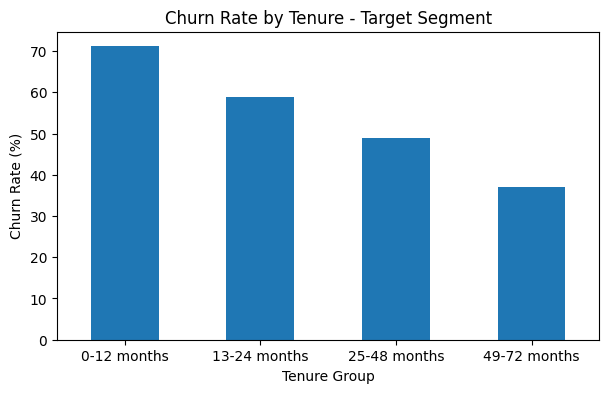

In [41]:
segment_tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Churn Rate by Tenure - Target Segment")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()